In [1]:
!pip install -q transformers torch pillow

In [4]:
from transformers import BlipProcessor, BlipForConditionalGeneration
from PIL import Image
import torch

# Load the pretrained Image-to-Text model
model_name = "Salesforce/blip-image-captioning-base"

processor = BlipProcessor.from_pretrained(model_name)
model = BlipForConditionalGeneration.from_pretrained(model_name)

# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print("Image-to-Text model loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Image-to-Text model loaded successfully!


Saving plane.jpg to plane.jpg


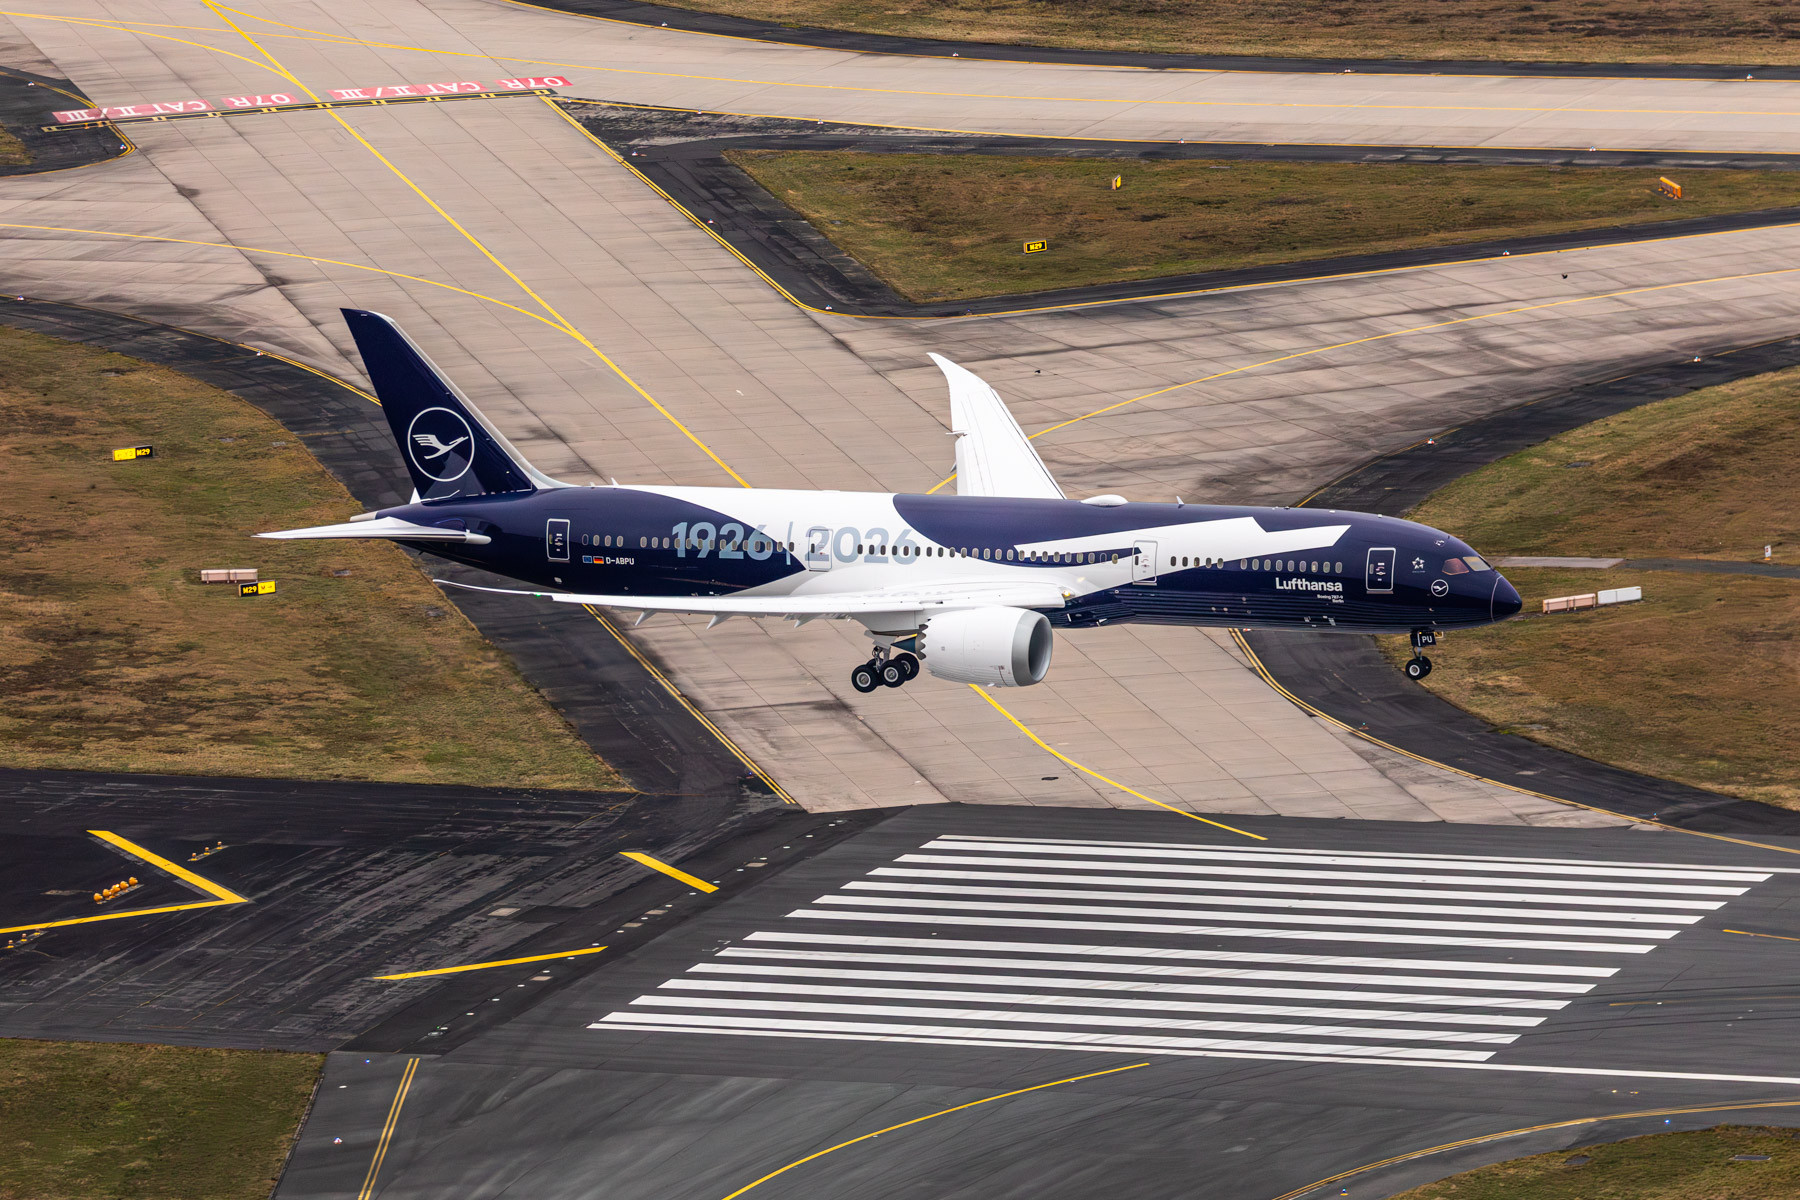

In [7]:
from google.colab import files

uploaded = files.upload()

# Get the uploaded image filename
image_path = next(iter(uploaded))

# Open and display the image
image = Image.open(image_path).convert("RGB")
display(image)

In [8]:
# Prepare the image for the model
inputs = processor(images=image, return_tensors="pt").to(device)

# Generate a text description
with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=100
    )

# Decode the generated text
description = processor.decode(output[0], skip_special_tokens=True)

print("\nImage-to-Text Output:")
print(description)


Image-to-Text Output:
a large passenger jet flying over a runway
